# Hoja de Trabajo #2 — Transformers y Mecanismos de Atención

**CC3092 Deep Learning y Sistemas Inteligentes**

Parte 1: primitivas de atención en PyTorch (scaled dot-product, `nn.MultiheadAttention`, máscaras, codificación posicional).
Parte 2: visualización y análisis de la atención en **BERT** (`bert-base-uncased`) y **GPT-2** (`gpt2`): mapas de calor,
correferencia, atención causal, *attention sinks* y entropía por capa.

## 0. Imports y configuración

In [1]:
import math
import random

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import torch
import torch.nn as nn
import torch.nn.functional as F

SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
torch.set_printoptions(precision=4, sci_mode=False, linewidth=120)
plt.rcParams.update({"figure.dpi": 110, "axes.titlesize": 10})

# Parte 1 — Atención en PyTorch

## 1.1 Scaled dot-product attention paso a paso

`Attention(Q, K, V) = softmax(Q Kᵀ / √d_k) V`. La división por `√d_k` mantiene la varianza de los productos punto en ~1:
si las componentes de `q` y `k` son independientes con media 0 y varianza 1, `q·k` tiene varianza `d_k`, y sin escalar
el softmax se satura (gradientes casi nulos). Ejemplo manual con 3 tokens y `d_k = 4`:

In [2]:
Q = torch.tensor([[1., 0., 1., 0.],
                  [0., 2., 0., 2.],
                  [1., 1., 0., 0.]])
K = torch.tensor([[1., 0., 0., 1.],
                  [0., 1., 1., 0.],
                  [1., 1., 1., 1.]])
V = torch.tensor([[1., 0., 0.],
                  [0., 2., 0.],
                  [0., 0., 3.]])
dk = Q.shape[-1]

S = Q @ K.T                      # 1) scores crudos
S_scaled = S / math.sqrt(dk)     # 2) escalar por sqrt(d_k) = 2
A = torch.softmax(S_scaled, -1)  # 3) softmax por fila
out = A @ V                      # 4) promedio ponderado de V
for n, t in [("Q Kᵀ", S), ("Q Kᵀ / √d_k", S_scaled), ("A = softmax(·)", A), ("A V", out)]:
    print(f"{n}:\n{t}\n")

ref = F.scaled_dot_product_attention(Q[None], K[None], V[None])[0]
assert torch.allclose(out, ref, atol=1e-6), "no coincide con F.scaled_dot_product_attention"
print("OK: coincide con F.scaled_dot_product_attention;  filas de A suman", A.sum(-1))

Q Kᵀ:
tensor([[1., 1., 2.],
        [2., 2., 4.],
        [1., 1., 2.]])

Q Kᵀ / √d_k:
tensor([[0.5000, 0.5000, 1.0000],
        [1.0000, 1.0000, 2.0000],
        [0.5000, 0.5000, 1.0000]])

A = softmax(·):
tensor([[0.2741, 0.2741, 0.4519],
        [0.2119, 0.2119, 0.5761],
        [0.2741, 0.2741, 0.4519]])

A V:
tensor([[0.2741, 0.5481, 1.3556],
        [0.2119, 0.4239, 1.7284],
        [0.2741, 0.5481, 1.3556]])

OK: coincide con F.scaled_dot_product_attention;  filas de A suman tensor([1., 1., 1.])


In [3]:
# Con máscara causal: el token i solo atiende a j <= i
T = Q.shape[0]
causal = torch.tril(torch.ones(T, T, dtype=torch.bool))
A_c = torch.softmax(S_scaled.masked_fill(~causal, float("-inf")), -1)
ref_c = F.scaled_dot_product_attention(Q[None], K[None], V[None], is_causal=True)[0]
assert torch.allclose(A_c @ V, ref_c, atol=1e-6)
print("A causal:\n", A_c)

A causal:
 tensor([[1.0000, 0.0000, 0.0000],
        [0.5000, 0.5000, 0.0000],
        [0.2741, 0.2741, 0.4519]])


## 1.2 `nn.MultiheadAttention`

Cada cabeza proyecta `x` a su propio subespacio (`d_k = d_model / h`), atiende en paralelo y las salidas se concatenan y
proyectan con `W_O`. Se verifica contra una implementación manual a partir de `in_proj_weight`.

In [4]:
d_model, h, T = 8, 2, 5
mha = nn.MultiheadAttention(d_model, h, batch_first=True).eval()
x = torch.randn(1, T, d_model)
with torch.no_grad():
    out, w = mha(x, x, x, need_weights=True, average_attn_weights=False)
print("salida:", tuple(out.shape), "| pesos por cabeza:", tuple(w.shape), "(batch, heads, T, T)")

# --- manual
Wq, Wk, Wv = mha.in_proj_weight.chunk(3)
bq, bk, bv = mha.in_proj_bias.chunk(3)
q, k, v = (x[0] @ Wq.T + bq), (x[0] @ Wk.T + bk), (x[0] @ Wv.T + bv)
split = lambda t: t.view(T, h, d_model // h).transpose(0, 1)       # (h, T, d_k)
qh, kh, vh = split(q), split(k), split(v)
att = torch.softmax(qh @ kh.transpose(-1, -2) / math.sqrt(d_model // h), -1)  # (h, T, T)
cat = (att @ vh).transpose(0, 1).reshape(T, d_model)                           # concatenar cabezas
manual = cat @ mha.out_proj.weight.T + mha.out_proj.bias
assert torch.allclose(att, w[0], atol=1e-5) and torch.allclose(manual, out[0], atol=1e-5)
print("OK: pesos y salida coinciden con la implementación manual")

salida: (1, 5, 8) | pesos por cabeza: (1, 2, 5, 5) (batch, heads, T, T)
OK: pesos y salida coinciden con la implementación manual


## 1.3 Máscaras

`nn.Transformer.generate_square_subsequent_mask(n)` devuelve una máscara **aditiva** (`-inf` sobre la diagonal, `0` en el resto).
Se suma a los scores antes del softmax. Un `key_padding_mask` booleano (`True` = ignorar) anula los tokens de relleno.

tensor([[0., -inf, -inf, -inf, -inf],
        [0., 0., -inf, -inf, -inf],
        [0., 0., 0., -inf, -inf],
        [0., 0., 0., 0., -inf],
        [0., 0., 0., 0., 0.]])
OK: peso 0 sobre posiciones futuras (causal) y sobre relleno (padding)


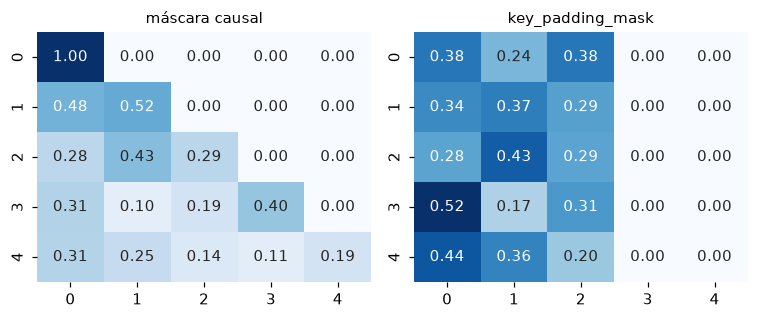

In [5]:
m = nn.Transformer.generate_square_subsequent_mask(5)
print(m)
with torch.no_grad():
    _, w_mask = mha(x, x, x, attn_mask=m, need_weights=True, average_attn_weights=False)
    pad = torch.tensor([[False, False, False, True, True]])      # últimos 2 tokens son relleno
    _, w_pad = mha(x, x, x, key_padding_mask=pad, need_weights=True, average_attn_weights=False)
assert torch.triu(w_mask[0, 0], diagonal=1).abs().max() == 0
assert w_pad[0, :, :, 3:].abs().max() == 0
print("OK: peso 0 sobre posiciones futuras (causal) y sobre relleno (padding)")
fig, axs = plt.subplots(1, 2, figsize=(7, 3))
sns.heatmap(w_mask[0, 0], ax=axs[0], cmap="Blues", cbar=False, annot=True, fmt=".2f"); axs[0].set_title("máscara causal")
sns.heatmap(w_pad[0, 0], ax=axs[1], cmap="Blues", cbar=False, annot=True, fmt=".2f"); axs[1].set_title("key_padding_mask")
plt.tight_layout(); plt.savefig("masks.png", dpi=150); plt.show()

## 1.4 Codificación posicional: sinusoidal vs RoPE

**Sinusoidal** (Vaswani et al.): `PE(pos, 2i) = sin(pos / 10000^{2i/d})`, `PE(pos, 2i+1) = cos(·)`; se **suma** al embedding.
**RoPE** (Su et al., 2021): se **rota** cada par de dimensiones de `q` y `k` un ángulo `pos·θ_i`; el producto `q_m · k_n`
depende solo de la posición relativa `m − n`.

q_m·k_n con m-n = 2: {(3, 1): -6.36248, (10, 8): -6.36248, (103, 101): -6.36248}
OK: el producto depende solo de m-n;  sin RoPE (3,1) vs (10,8): -4.361624240875244 (constante, ignora posición)


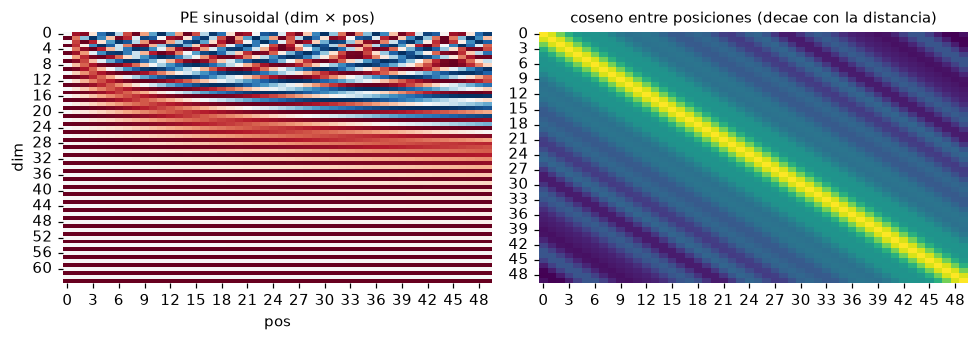

In [6]:
def sinusoidal_pe(T, d):
    pos = torch.arange(T)[:, None]
    i = torch.arange(0, d, 2)[None]
    pe = torch.zeros(T, d)
    pe[:, 0::2] = torch.sin(pos / 10000 ** (i / d)); pe[:, 1::2] = torch.cos(pos / 10000 ** (i / d))
    return pe

def rope(x, pos, base=10000.0):
    """x: (d,) con d par; rota cada par (x_{2i}, x_{2i+1}) por pos * base^{-2i/d}."""
    d = x.shape[-1]
    ang = pos * base ** (-torch.arange(0, d, 2) / d)
    c, s = torch.cos(ang), torch.sin(ang)
    x1, x2 = x[0::2], x[1::2]
    out = torch.empty_like(x); out[0::2] = x1 * c - x2 * s; out[1::2] = x1 * s + x2 * c
    return out

q0, k0 = torch.randn(64), torch.randn(64)
dots = {(m, n): float(rope(q0, m) @ rope(k0, n)) for m, n in [(3, 1), (10, 8), (103, 101)]}
print("q_m·k_n con m-n = 2:", {k: round(v, 5) for k, v in dots.items()})
assert max(dots.values()) - min(dots.values()) < 1e-4
print("OK: el producto depende solo de m-n;  sin RoPE (3,1) vs (10,8):", float(q0 @ k0), "(constante, ignora posición)")

pe = sinusoidal_pe(50, 64)
fig, axs = plt.subplots(1, 2, figsize=(9, 3.2))
sns.heatmap(pe.T, ax=axs[0], cmap="RdBu_r", center=0, cbar=False); axs[0].set(title="PE sinusoidal (dim × pos)", xlabel="pos", ylabel="dim")
sim = F.normalize(pe, dim=1) @ F.normalize(pe, dim=1).T
sns.heatmap(sim, ax=axs[1], cmap="viridis", cbar=False); axs[1].set(title="coseno entre posiciones (decae con la distancia)")
plt.tight_layout(); plt.savefig("posenc.png", dpi=150); plt.show()